In [5]:
# ============================================================
# 05_inference_kaggle.ipynb — Run DistilBERT on ALL reviews
#
# This notebook runs the fine-tuned model on every review in
# the full dataset (train + val + test combined) and saves:
#   - distilbert_sentiment : predicted class (Positive/Negative)
#   - prob_positive        : P(Positive), the confidence score
#   - prob_negative        : P(Negative)
#
# The prob_positive column is the KEY output.
# It is a continuous score in [0, 1] representing how positively
# the model reads each review snippet.
# 0.99 = extremely positive | 0.51 = barely positive | 0.01 = very negative
# This is what makes System 2 richer than simple field counting.
#
# KAGGLE SETUP:
#   1. Attach your data dataset (train.csv, val.csv, test.csv)
#      Same dataset as 04_distilbert.ipynb
#   2. Attach your model weights dataset named 'distilbert-weights-2'
#      (from distilbert_best_final.zip downloaded in notebook 04)
#   3. Enable GPU: Settings → Accelerator → GPU T4 x2
#   4. Run all cells.
#      Download predictions.zip and place the CSV in data/processed/
# ============================================================

In [6]:
import os, gc
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification
import matplotlib.pyplot as plt
import shutil
from IPython.display import FileLink, display
import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

Device: cuda


In [7]:
# ── 1. LOAD MODEL ────────────────────────────────────────────
MODEL_DIR = '/kaggle/input/datasets/sarahdje/distilbert-weights-2'  # <-- update to your weights dataset path

label2id = {'Negative': 0, 'Positive': 1}
id2label  = {0: 'Negative', 1: 'Positive'}

tokenizer = DistilBertTokenizer.from_pretrained(MODEL_DIR)
model = DistilBertForSequenceClassification.from_pretrained(
    MODEL_DIR,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
)
model.to(device)
model.eval()
print("Model loaded successfully.")
print(f"Labels: {id2label}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model loaded successfully.
Labels: {0: 'Negative', 1: 'Positive'}


In [8]:
# ── 2. LOAD ALL REVIEWS ──────────────────────────────────────
# train/val/test have: clean_text, bert_text, label
# clean_reviews.csv has: clean_text, bert_text, label, Hotel_Name,
#                        Average_Score, Reviewer_Score
#
# We load clean_reviews.csv directly since it has everything we need
# for inference AND the hotel/score columns for the recommendation.

DATA_PATH = '/kaggle/input/datasets/sarahdje/hotel-reviews-nlp-3'

full_df = pd.read_csv(f'{DATA_PATH}/clean_reviews.csv').dropna(subset=['bert_text']).reset_index(drop=True)

# Rename to consistent names used throughout the pipeline
full_df = full_df.rename(columns={
    'Hotel_Name'    : 'hotel',
    'Average_Score' : 'average_score',
    'Reviewer_Score': 'score'
})

# Shuffle so Positive and Negative snippets are interleaved
full_df = full_df.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Full dataset : {len(full_df):,} review snippets")
print(f"Columns      : {list(full_df.columns)}")
print(f"Hotels       : {full_df['hotel'].nunique():,}")
print(f"\nLabel distribution:")
print(full_df['label'].value_counts())
print(f"\nReviewer score stats:")
print(full_df['score'].describe())

Full dataset : 709,313 review snippets
Columns      : ['clean_text', 'bert_text', 'label', 'hotel', 'average_score', 'score']
Hotels       : 1,492

Label distribution:
label
Positive    399453
Negative    309860
Name: count, dtype: int64

Reviewer score stats:
count    709313.000000
mean          8.332838
std           1.589807
min           2.500000
25%           7.500000
50%           8.800000
75%           9.600000
max          10.000000
Name: score, dtype: float64


In [9]:
# ── 3. INFERENCE DATASET ─────────────────────────────────────
MAX_LENGTH = 128

class ReviewDataset(Dataset):
    def __init__(self, texts, tokenizer, max_length=MAX_LENGTH):
        self.texts      = texts.tolist()
        self.tokenizer  = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            str(self.texts[idx]),
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids'     : encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
        }

# bert_text — natural English, what DistilBERT was pretrained on
dataset = ReviewDataset(full_df['bert_text'], tokenizer)
loader  = DataLoader(dataset, batch_size=256, shuffle=False,
                     num_workers=2, pin_memory=True)

print(f"Total batches : {len(loader):,}")
print(f"Expected time : ~5-10 minutes on GPU T4")

Total batches : 2,771
Expected time : ~5-10 minutes on GPU T4


In [10]:
# ── 4. RUN INFERENCE ─────────────────────────────────────────
# For each review snippet we save the full softmax output:
#   prob_negative = P(Negative)  — how confident the model is it is negative
#   prob_positive = P(Positive)  — how confident the model is it is positive
#
# Note: prob_negative + prob_positive = 1.0 always.
#
# A snippet with prob_positive=0.97 is strongly positive.
# A snippet with prob_positive=0.53 is barely positive.
# When we average prob_positive per hotel, weakly positive and weakly
# negative snippets drag the score toward 0.5, while strongly worded
# reviews push it toward 0 or 1. This is the key advantage over counting.

print(f"Running inference on {len(full_df):,} review snippets...")

all_probs = []

with torch.no_grad():
    for batch_idx, batch in enumerate(loader):
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)

        # Softmax over logits → probabilities [P(Neg), P(Pos)] per review
        probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()
        all_probs.extend(probs.tolist())

        if (batch_idx + 1) % 50 == 0:
            pct = (batch_idx + 1) / len(loader) * 100
            print(f"  Batch {batch_idx+1:,}/{len(loader):,} — {pct:.1f}% done")

        gc.collect()

# Attach results to dataframe
full_df['prob_negative']        = [p[0] for p in all_probs]
full_df['prob_positive']        = [p[1] for p in all_probs]
full_df['distilbert_sentiment'] = ['Positive' if p[1] >= 0.5 else 'Negative'
                                    for p in all_probs]

print(f"\nInference complete.")
print(f"\nPredicted label distribution:")
print(full_df['distilbert_sentiment'].value_counts())
print(f"\nColumn-origin label distribution (for reference):")
print(full_df['label'].value_counts())
print(f"\nP(Positive) statistics:")
print(full_df['prob_positive'].describe())

Running inference on 709,313 review snippets...
  Batch 50/2,771 — 1.8% done
  Batch 100/2,771 — 3.6% done
  Batch 150/2,771 — 5.4% done
  Batch 200/2,771 — 7.2% done
  Batch 250/2,771 — 9.0% done
  Batch 300/2,771 — 10.8% done
  Batch 350/2,771 — 12.6% done
  Batch 400/2,771 — 14.4% done
  Batch 450/2,771 — 16.2% done
  Batch 500/2,771 — 18.0% done
  Batch 550/2,771 — 19.8% done
  Batch 600/2,771 — 21.7% done
  Batch 650/2,771 — 23.5% done
  Batch 700/2,771 — 25.3% done
  Batch 750/2,771 — 27.1% done
  Batch 800/2,771 — 28.9% done
  Batch 850/2,771 — 30.7% done
  Batch 900/2,771 — 32.5% done
  Batch 950/2,771 — 34.3% done
  Batch 1,000/2,771 — 36.1% done
  Batch 1,050/2,771 — 37.9% done
  Batch 1,100/2,771 — 39.7% done
  Batch 1,150/2,771 — 41.5% done
  Batch 1,200/2,771 — 43.3% done
  Batch 1,250/2,771 — 45.1% done
  Batch 1,300/2,771 — 46.9% done
  Batch 1,350/2,771 — 48.7% done
  Batch 1,400/2,771 — 50.5% done
  Batch 1,450/2,771 — 52.3% done
  Batch 1,500/2,771 — 54.1% done
  Batc

Confidence breakdown across full dataset:
  High confidence   (>90% sure) : 691,282  (97.5%)
  Medium confidence (70-90%)    : 12,537  (1.8%)
  Low confidence    (50-70%)    : 5,494  (0.8%)

Agreement with column-origin labels: 98.0%
(This tells us the model learned the task correctly —
 it does not mean the model is trivial, because it also
 assigns DIFFERENT confidence levels to different reviews)


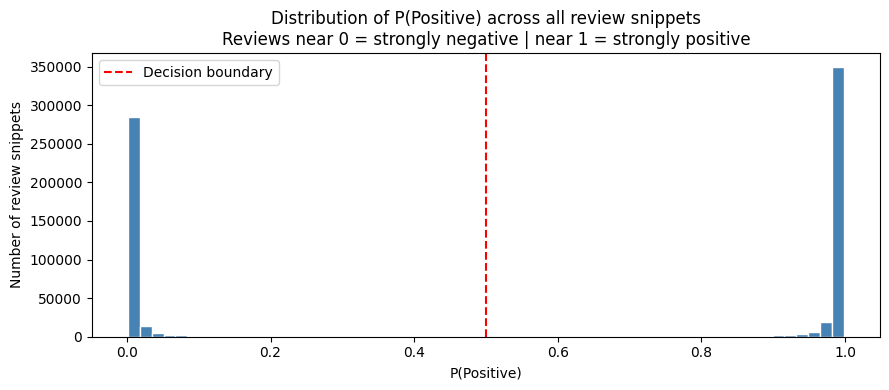

/kaggle/working/confidence_distribution_full.png

In [11]:
# ── 5. CONFIDENCE ANALYSIS ───────────────────────────────────
# This shows how decisive the model is across the full dataset.
# A well-trained model should have most reviews far from 0.5.

total = len(full_df)
high   = ((full_df['prob_positive'] > 0.9) | (full_df['prob_positive'] < 0.1)).sum()
medium = (((full_df['prob_positive'] > 0.7) & (full_df['prob_positive'] <= 0.9)) |
          ((full_df['prob_positive'] >= 0.1) & (full_df['prob_positive'] < 0.3))).sum()
low    = ((full_df['prob_positive'] >= 0.3) & (full_df['prob_positive'] <= 0.7)).sum()

print("Confidence breakdown across full dataset:")
print(f"  High confidence   (>90% sure) : {high:,}  ({high/total*100:.1f}%)")
print(f"  Medium confidence (70-90%)    : {medium:,}  ({medium/total*100:.1f}%)")
print(f"  Low confidence    (50-70%)    : {low:,}  ({low/total*100:.1f}%)")
print()

# Agreement with column-origin labels (sanity check)
agreement = (full_df['label'] == full_df['distilbert_sentiment']).mean() * 100
print(f"Agreement with column-origin labels: {agreement:.1f}%")
print("(This tells us the model learned the task correctly —")
print(" it does not mean the model is trivial, because it also")
print(" assigns DIFFERENT confidence levels to different reviews)")

# P(Positive) distribution plot
plt.figure(figsize=(9, 4))
plt.hist(full_df['prob_positive'], bins=60, color='steelblue', edgecolor='white')
plt.axvline(0.5, color='red', linestyle='--', label='Decision boundary')
plt.title('Distribution of P(Positive) across all review snippets\n'
          'Reviews near 0 = strongly negative | near 1 = strongly positive')
plt.xlabel('P(Positive)')
plt.ylabel('Number of review snippets')
plt.legend()
plt.tight_layout()
plt.savefig('/kaggle/working/confidence_distribution_full.png', dpi=150)
plt.show()
display(FileLink('confidence_distribution_full.png'))

In [12]:
# ── 6. SAVE OUTPUT ───────────────────────────────────────────
output_path = '/kaggle/working/hotel_reviews_with_predictions.csv'

full_df[['hotel', 'score', 'label',
         'distilbert_sentiment', 'prob_positive', 'prob_negative']].to_csv(
    output_path, index=False
)

print(f"Saved: {output_path}")
print(f"Rows : {len(full_df):,}")
print(f"Size : {os.path.getsize(output_path)/1e6:.1f} MB")
print()
print("Sample output:")
print(full_df[['hotel', 'score', 'label',
               'distilbert_sentiment', 'prob_positive',
               'prob_negative']].head(8).to_string(index=False))

shutil.make_archive('/kaggle/working/predictions', 'zip',
                    '/kaggle/working', 'hotel_reviews_with_predictions.csv')
display(FileLink('predictions.zip'))
print("\n^^^ Download predictions.zip ^^^")
print("Place hotel_reviews_with_predictions.csv in: data/processed/")

Saved: /kaggle/working/hotel_reviews_with_predictions.csv
Rows : 709,313
Size : 62.8 MB

Sample output:
                               hotel  score    label distilbert_sentiment  prob_positive  prob_negative
                  The Hoxton Holborn    9.6 Negative             Negative       0.002519       0.997481
           Pullman Paris Tour Eiffel    5.8 Positive             Positive       0.979702       0.020298
Park Plaza Westminster Bridge London    9.6 Negative             Negative       0.001378       0.998622
                      Fielding Hotel    9.6 Negative             Negative       0.004780       0.995220
              Nottingham Place Hotel    8.3 Positive             Positive       0.994813       0.005187
       Hilton London Angel Islington    6.7 Positive             Positive       0.998333       0.001667
       H tel Aiglon Esprit de France    9.6 Negative             Negative       0.001667       0.998334
                The Principal London    9.2 Negative            

/kaggle/working/predictions.zip


^^^ Download predictions.zip ^^^
Place hotel_reviews_with_predictions.csv in: data/processed/
